<a href="https://colab.research.google.com/github/Bibatshu95/Hum-to-Harmony/blob/main/notebook/02_dataset_and_markov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone -q https://github.com/jukedeck/nottingham-dataset.git
!pip install -q pretty_midi librosa
import glob, random, warnings
import numpy as np, pretty_midi, librosa
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from IPython.display import Audio, display
warnings.simplefilter("ignore")

In [2]:
files = sorted(glob.glob("nottingham-dataset/MIDI/melody/*.mid"))
tunes = []
for f in files:
    pm = pretty_midi.PrettyMIDI(f)
    notes = sorted(pm.instruments[0].notes, key=lambda n: n.start)
    pitches = [n.pitch for n in notes]
    if len(pitches) >= 16:          # skip tiny fragments
        tunes.append(pitches)

print("Tunes:", len(tunes))
print("Total notes:", sum(len(t) for t in tunes))
all_p = [p for t in tunes for p in t]
print("Pitch range:", pretty_midi.note_number_to_name(min(all_p)), "to",
      pretty_midi.note_number_to_name(max(all_p)))

Tunes: 1034
Total notes: 196961
Pitch range: G3 to E6


Most common steps: [(-2, 37399), (2, 32111), (0, 22395), (1, 16229), (-1, 15685), (-3, 15541), (3, 11208), (-4, 9222)]


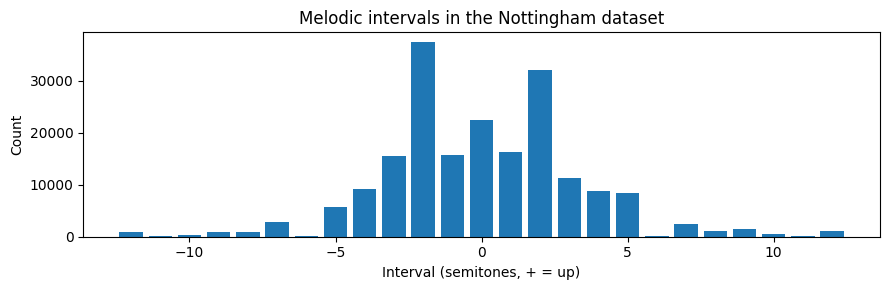

In [3]:
intervals = [[b - a for a, b in zip(t, t[1:])] for t in tunes]
ic = Counter(i for t in intervals for i in t)
print("Most common steps:", ic.most_common(8))

plt.figure(figsize=(9, 3))
steps = range(-12, 13)
plt.bar(steps, [ic[s] for s in steps])
plt.xlabel("Interval (semitones, + = up)"); plt.ylabel("Count")
plt.title("Melodic intervals in the Nottingham dataset")
plt.tight_layout(); plt.savefig("intervals_hist.png", dpi=150); plt.show()

In [4]:
random.seed(42)
idx = list(range(len(intervals))); random.shuffle(idx)
cut = int(0.8 * len(idx))
train = [intervals[i] for i in idx[:cut]]
test  = [intervals[i] for i in idx[cut:]]

ORDER = 2   # look at the last 2 steps to predict the next one
counts = defaultdict(Counter)
for t in train:
    for k in range(ORDER, len(t)):
        counts[tuple(t[k-ORDER:k])][t[k]] += 1
overall = Counter(i for t in train for i in t)   # fallback if a context was never seen
print("Contexts learned:", len(counts))

Contexts learned: 545


In [5]:
hit = total = 0
for t in test:
    for k in range(ORDER, len(t)):
        c = counts.get(tuple(t[k-ORDER:k]))
        guess = (c or overall).most_common(1)[0][0]
        hit += guess == t[k]; total += 1
naive = overall.most_common(1)[0][1] / sum(overall.values())
print(f"Markov accuracy on unseen tunes: {hit/total:.1%}")
print(f"Naive baseline (always guess the most common step): {naive:.1%}")

Markov accuracy on unseen tunes: 33.2%
Naive baseline (always guess the most common step): 18.9%


In [7]:
!ffmpeg -loglevel error -y -i "hum 4.mp4" -vn -ac 1 -ar 22050 hum_4.wav

In [9]:
from numpy.lib.stride_tricks import sliding_window_view

def transcribe(file, gate_db=None, smooth=1, min_len=0.1):
    y, sr = librosa.load(file, sr=22050)
    f0, voiced, _ = librosa.pyin(y, fmin=librosa.note_to_hz("C2"),
                                 fmax=librosa.note_to_hz("C6"), sr=sr)
    times = librosa.times_like(f0, sr=sr)
    keep = voiced.copy()
    if gate_db is not None:                       # loudness gate
        rms = librosa.feature.rms(y=y)[0][:len(f0)]
        keep &= librosa.amplitude_to_db(rms, ref=np.max) > -gate_db
    midi_f = np.where(keep, librosa.hz_to_midi(f0), np.nan)
    if smooth > 1:                                # median smoothing
        p = smooth // 2
        win = sliding_window_view(np.pad(midi_f, p, constant_values=np.nan), smooth)
        midi_f = np.where(keep, np.nanmedian(win, axis=1), np.nan)
    midi = np.round(midi_f)
    notes, cur, start = [], None, 0.0
    for t, m in zip(times, midi):
        m = None if np.isnan(m) else int(m)
        if m != cur:
            if cur is not None and t - start >= min_len:
                notes.append(librosa.midi_to_note(cur))
            cur, start = m, t
    if cur is not None and times[-1] - start >= min_len:
        notes.append(librosa.midi_to_note(cur))
    return notes

In [10]:
def sample_next(ctx, temp=1.0):
    c = counts.get(tuple(ctx[-ORDER:])) or overall
    keys = list(c)
    p = np.array([c[k] for k in keys], float) ** (1 / temp)
    return int(np.random.choice(keys, p=p / p.sum()))

def continue_melody(start, n=8, temp=1.0):
    ivs = [b - a for a, b in zip(start, start[1:])]
    out = list(start)
    for _ in range(n):
        step = sample_next(ivs, temp); ivs.append(step); out.append(out[-1] + step)
    return out[len(start):]

def play(pitches, dur=0.4):
    pm = pretty_midi.PrettyMIDI(); inst = pretty_midi.Instrument(program=0); t = 0
    for p in pitches:
        inst.notes.append(pretty_midi.Note(velocity=90, pitch=int(p), start=t, end=t + dur * 0.9)); t += dur
    pm.instruments.append(inst)
    return Audio(pm.synthesize(fs=22050), rate=22050)

hum = [librosa.note_to_midi(n) for n in transcribe("hum_4.wav", gate_db=25)]
print("You hummed:", [librosa.midi_to_note(p) for p in hum])
np.random.seed(0)
for temp in [0.5, 1.0, 1.5]:
    cont = continue_melody(hum, n=8, temp=temp)
    print(f"temp={temp}:", [librosa.midi_to_note(p) for p in cont])
    display(play(hum + cont))

You hummed: ['C3', 'C3', 'C3', 'G3', 'G3', 'A3', 'A3', 'G♯3', 'G3']
temp=0.5: ['F♯3', 'G3', 'A3', 'B3', 'C4', 'G3', 'E3', 'F3']


temp=1.0: ['F4', 'D♯4', 'C♯4', 'F♯4', 'G♯4', 'C♯4', 'A4', 'E4']


temp=1.5: ['F3', 'D3', 'D♯3', 'A♯3', 'C♯4', 'C4', 'D♯4', 'D♯4']
